# Clustering Karyawan — K-Means Analysis

- **Dataset** : `Report.xlsx`
- **Metode** : K-Means Clustering dengan MinMax Scaling
- **Evaluasi** : Elbow Method, Silhouette Score, Davies-Bouldin Index

## 1. Import Library

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
)
import joblib, os, json
from collections import Counter

print('done')

done


## 2. Load & Preprocessing Data

In [34]:
#  Load 
df = pd.read_csv('Report.csv')

kolom_yang_dipilih = [
    'Username',
    'Tanggal Visit',
    'Area',
    'Nama Karyawan',
    'Region',
    'Facing',
    'Is FIFO/FEFO',
    'Is Price Tag Available'
]
df = df[kolom_yang_dipilih].copy()

#  Tipe data dasar
df['Tanggal Visit'] = pd.to_datetime(df['Tanggal Visit'], errors='coerce')
df['Facing']        = pd.to_numeric(df['Facing'], errors='coerce').fillna(0).clip(lower=0)
df['Is FIFO/FEFO']           = df['Is FIFO/FEFO'].astype(str).str.upper().str.strip()
df['Is Price Tag Available'] = df['Is Price Tag Available'].astype(str).str.upper().str.strip()

#  FILTER 1 — Username harus berformat ID-XXXXXXX 
# Username seperti PERMATA GROUP, SAT, SAT-LARGE = data produk/brand
n_sebelum = len(df)
df        = df[df['Username'].astype(str).str.match(r'^ID-', na=False)].copy()
print(f"Baris dibuang (Username bukan ID-xxx) : {n_sebelum - len(df)}")
print(f"Baris tersisa (karyawan valid)        : {len(df)}")

#  FILTER 2 — Buang FIFO/FEFO = '-1' (sentinel data kotor) 
mask_invalid = df['Is FIFO/FEFO'] == '-1'
print(f"Baris dengan FIFO/FEFO=-1 dibuang     : {mask_invalid.sum()}")
df = df[~mask_invalid].copy()

#  FILTER 3  Normalisasi KPI: nilai selain YA/TIDAK → TIDAK 
valid_kpi = {'YA', 'TIDAK'}
df['Is FIFO/FEFO'] = df['Is FIFO/FEFO'].apply(
    lambda x: x if x in valid_kpi else 'TIDAK'
)
df['Is Price Tag Available'] = df['Is Price Tag Available'].apply(
    lambda x: x if x in valid_kpi else 'TIDAK'
)

#  Verifikasi distribusi 
print()
print('Distribusi Is FIFO/FEFO  :', df['Is FIFO/FEFO'].value_counts().to_dict())
print('Distribusi Price Tag     :', df['Is Price Tag Available'].value_counts().to_dict())
print('Facing min / max         :', df['Facing'].min(), '/', df['Facing'].max())

#  Buat Report_Clean (satu baris per karyawan unik) 
visit_count = df.groupby('Username')['Tanggal Visit'].count().reset_index()
visit_count.columns = ['Username', 'Visit Count']

df_clean = df.merge(visit_count, on='Username', how='left')
df_clean = df_clean.drop_duplicates(
    subset=['Username', 'Nama Karyawan', 'Region']
).reset_index(drop=True)

df_clean.to_excel('Report_Clean.xlsx', index=False)
print(f"\nReport_Clean.xlsx disimpan: {df_clean.shape[0]} baris, {df_clean.shape[1]} kolom")

#  Groupby per Username untuk clustering 
feature_cols = ['visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']

df_grouped = (
    df.groupby('Username')
    .agg(
        Facing      = ('Facing',                 'mean'),
        Is_FIFO     = ('Is FIFO/FEFO',           lambda x: (x == 'YA').mean()),
        Is_PriceTag = ('Is Price Tag Available', lambda x: (x == 'YA').mean()),
        visit_count = ('Tanggal Visit',          'count'),
    )
    .rename(columns={
        'Is_FIFO'    : 'Is FIFO/FEFO',
        'Is_PriceTag': 'Is Price Tag Available',
    })
    .reset_index()
    .fillna(0)
)

employee_info = df[['Username', 'Nama Karyawan', 'Area', 'Region']].drop_duplicates('Username')

print(f'Total karyawan valid untuk clustering: {len(df_grouped)}')
df_grouped.describe().round(3)

Baris dibuang (Username bukan ID-xxx) : 536
Baris tersisa (karyawan valid)        : 1048039
Baris dengan FIFO/FEFO=-1 dibuang     : 0

Distribusi Is FIFO/FEFO  : {'TIDAK': 1048039}
Distribusi Price Tag     : {'TIDAK': 1048039}
Facing min / max         : 0.0 / 8000.0

Report_Clean.xlsx disimpan: 112 baris, 9 kolom
Total karyawan valid untuk clustering: 86


,Facing,Is FIFO/FEFO,Is Price Tag Available,visit_count
count,86.000,86.0,86.0,86.000
mean,1.056,0.0,0.0,12186.500
std,0.455,0.0,0.0,5685.816
min,0.160,0.0,0.0,559.000
25%,0.784,0.0,0.0,8533.250
50%,0.968,0.0,0.0,12545.500
75%,1.283,0.0,0.0,15417.250
max,2.473,0.0,0.0,29663.000


## 3. Distribusi Data — Sebelum & Sesudah Scaling

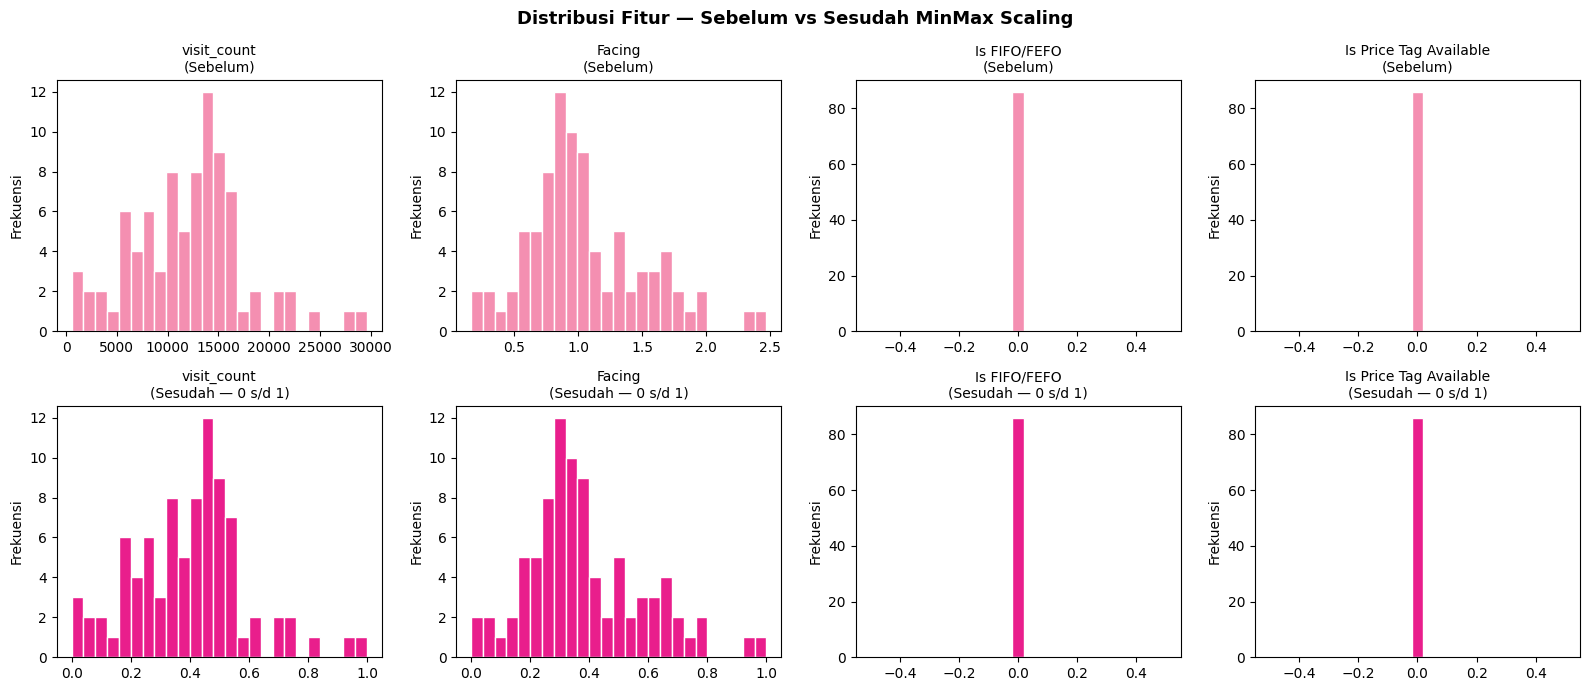


Statistik setelah scaling:
  Min : [0. 0. 0. 0.]
  Max : [1. 1. 0. 0.]
  Mean: [0.4   0.387 0.    0.   ]


In [35]:
X = df_grouped[feature_cols].values

scaler   = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle('Distribusi Fitur — Sebelum vs Sesudah MinMax Scaling', fontsize=13, fontweight='bold')

for i, col in enumerate(feature_cols):
    axes[0, i].hist(X[:, i],        bins=25, color='#F48FB1', edgecolor='white')
    axes[0, i].set_title(f'{col}\n(Sebelum)', fontsize=10)
    axes[0, i].set_ylabel('Frekuensi')

    axes[1, i].hist(X_scaled[:, i], bins=25, color='#E91E8C', edgecolor='white')
    axes[1, i].set_title(f'{col}\n(Sesudah — 0 s/d 1)', fontsize=10)
    axes[1, i].set_ylabel('Frekuensi')

plt.tight_layout()
plt.savefig('plot_distribusi.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nStatistik setelah scaling:')
print(f'  Min : {X_scaled.min(axis=0).round(3)}')
print(f'  Max : {X_scaled.max(axis=0).round(3)}')
print(f'  Mean: {X_scaled.mean(axis=0).round(3)}')

## 4. Menentukan K Optimal — Elbow, Silhouette, Davies-Bouldin

In [36]:
K_RANGE = range(2, 11)

inertia_list = []
sil_list     = []
dbi_list     = []

for k in K_RANGE:
    km     = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertia_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_scaled, labels))
    dbi_list.append(davies_bouldin_score(X_scaled, labels))

#  Pilih K optimal via majority voting (2 metrik) 
# Silhouette : makin tinggi makin baik → ambil max
# DBI        : makin rendah makin baik → ambil min
best_sil_k = list(K_RANGE)[sil_list.index(max(sil_list))]
best_dbi_k = list(K_RANGE)[dbi_list.index(min(dbi_list))]

votes      = [best_sil_k, best_dbi_k]
vote_count = Counter(votes)
BEST_K     = vote_count.most_common(1)[0][0]

# Tie-break (keduanya berbeda) → Silhouette sebagai penentu
if best_sil_k != best_dbi_k:
    BEST_K    = best_sil_k
    tie_note  = '(tie-break → Silhouette)'
else:
    tie_note  = '(kedua metrik sepakat)'

print(f'\n=== Pemilihan K Optimal ===')
print(f'  Silhouette terbaik    : k={best_sil_k} ({max(sil_list):.4f})')
print(f'  Davies-Bouldin terbaik: k={best_dbi_k} ({min(dbi_list):.4f})')
print(f'  Hasil voting          : {votes}')
print(f'  K yang optimal        : k={BEST_K} {tie_note}')


=== Pemilihan K Optimal ===
  Silhouette terbaik    : k=4 (0.4743)
  Davies-Bouldin terbaik: k=4 (0.6582)
  Hasil voting          : [4, 4]
  K yang optimal        : k=4 (kedua metrik sepakat)


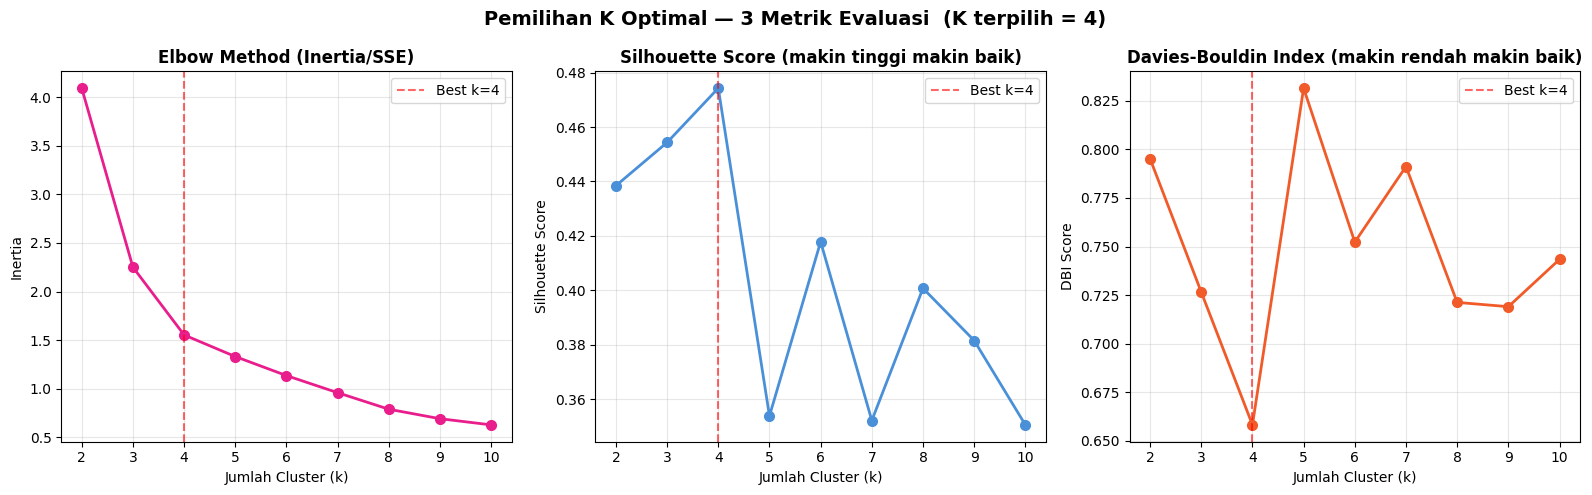


=== Tabel Evaluasi per K ===
 k  Inertia  Silhouette  Davies-Bouldin Terpilih
 2     4.09      0.4385          0.7952         
 3     2.25      0.4543          0.7265         
 4     1.55      0.4743          0.6582        ✅
 5     1.33      0.3539          0.8315         
 6     1.14      0.4179          0.7523         
 7     0.96      0.3522          0.7912         
 8     0.79      0.4008          0.7212         
 9     0.69      0.3816          0.7190         
10     0.63      0.3506          0.7434         


In [37]:
#  Plot 3 metrik 
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(f'Pemilihan K Optimal — 3 Metrik Evaluasi  (K terpilih = {BEST_K})',
             fontsize=14, fontweight='bold')

# Elbow
axes[0].plot(K_RANGE, inertia_list, 'o-', color='#E91E8C', linewidth=2, markersize=7)
axes[0].axvline(x=BEST_K, color='red', linestyle='--', alpha=0.6, label=f'Best k={BEST_K}')
axes[0].set_title('Elbow Method (Inertia/SSE)', fontweight='bold')
axes[0].set_xlabel('Jumlah Cluster (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)
axes[0].set_xticks(list(K_RANGE))
axes[0].legend()

# Silhouette
axes[1].plot(K_RANGE, sil_list, 'o-', color='#4A90D9', linewidth=2, markersize=7)
axes[1].axvline(x=best_sil_k, color='red', linestyle='--', alpha=0.6, label=f'Best k={best_sil_k}')
axes[1].set_title('Silhouette Score (makin tinggi makin baik)', fontweight='bold')
axes[1].set_xlabel('Jumlah Cluster (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xticks(list(K_RANGE))

# Davies-Bouldin
axes[2].plot(K_RANGE, dbi_list, 'o-', color='#F15A29', linewidth=2, markersize=7)
axes[2].axvline(x=best_dbi_k, color='red', linestyle='--', alpha=0.6, label=f'Best k={best_dbi_k}')
axes[2].set_title('Davies-Bouldin Index (makin rendah makin baik)', fontweight='bold')
axes[2].set_xlabel('Jumlah Cluster (k)')
axes[2].set_ylabel('DBI Score')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xticks(list(K_RANGE))

plt.tight_layout()
plt.savefig('plot_pemilihan_k.png', dpi=150, bbox_inches='tight')
plt.show()

#  Tabel evaluasi 
eval_df = pd.DataFrame({
    'k'             : list(K_RANGE),
    'Inertia'       : [round(v, 2) for v in inertia_list],
    'Silhouette'    : [round(v, 4) for v in sil_list],
    'Davies-Bouldin': [round(v, 4) for v in dbi_list],
    'Terpilih'      : ['✅' if k == BEST_K else '' for k in K_RANGE],
})
print('\n=== Tabel Evaluasi per K ===')
print(eval_df.to_string(index=False))

## 5. Training Model Final — K Optimal

In [38]:
print(f'\n> Training KMeans dengan k={BEST_K} (hasil voting Silhouette + DBI)')

kmeans_final = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
labels_final = kmeans_final.fit_predict(X_scaled)
df_grouped['cluster'] = labels_final

# Label otomatis berdasarkan rata-rata visit_count (descending)
cluster_visit_mean = (
    df_grouped.groupby('cluster')['visit_count']
    .mean()
    .sort_values(ascending=False)
)

# Konsisten dengan app.py — label harus cocok dengan _TIER_INTERP
_LABEL_MAP = {
    2: ['High', 'Moderate'],
    3: ['High', 'Medium', 'Low'],
    4: ['High', 'Medium-High', 'Medium-Low', 'Low'],
}
n        = len(cluster_visit_mean)
tier_seq = _LABEL_MAP.get(n)
rank_labels = {
    cid: (tier_seq[rank] if tier_seq else f'Tier {rank + 1}')
    for rank, (cid, _) in enumerate(cluster_visit_mean.items())
}

df_grouped['cluster_label'] = df_grouped['cluster'].map(rank_labels)

print(f'\nMapping cluster → label (berdasarkan visit_count rata-rata):')
for cid, lbl in rank_labels.items():
    n_kary = (labels_final == cid).sum()
    vm     = cluster_visit_mean[cid]
    print(f'  Cluster {cid} → {lbl:<12}  ({n_kary} karyawan, visit_mean={vm:.1f})')

print(f'\nCentroid (scaled):')
print(pd.DataFrame(kmeans_final.cluster_centers_, columns=feature_cols).round(4))


> Training KMeans dengan k=4 (hasil voting Silhouette + DBI)

Mapping cluster → label (berdasarkan visit_count rata-rata):
  Cluster 0 → High          (7 karyawan, visit_mean=24306.4)
  Cluster 1 → Medium-High   (43 karyawan, visit_mean=14283.5)
  Cluster 2 → Medium-Low    (18 karyawan, visit_mean=8591.4)
  Cluster 3 → Low           (18 karyawan, visit_mean=6058.8)

Centroid (scaled):
   visit_count  Facing  Is FIFO/FEFO  Is Price Tag Available
0       0.8160  0.3856           0.0                     0.0
1       0.4716  0.3454           0.0                     0.0
2       0.2760  0.6905           0.0                     0.0
3       0.1890  0.1844           0.0                     0.0


## 6. Evaluasi Model

    EVALUASI MODEL K-MEANS  (k=4)
  Silhouette Score     : 0.4743  → Lemah
  Davies-Bouldin Index : 0.6582  → Baik
  Inertia (SSE)        : 1.55
  Catatan:
  - Silhouette > 0.5 = cluster cukup terpisah
  - DBI < 1.0        = cluster tidak tumpang tindih


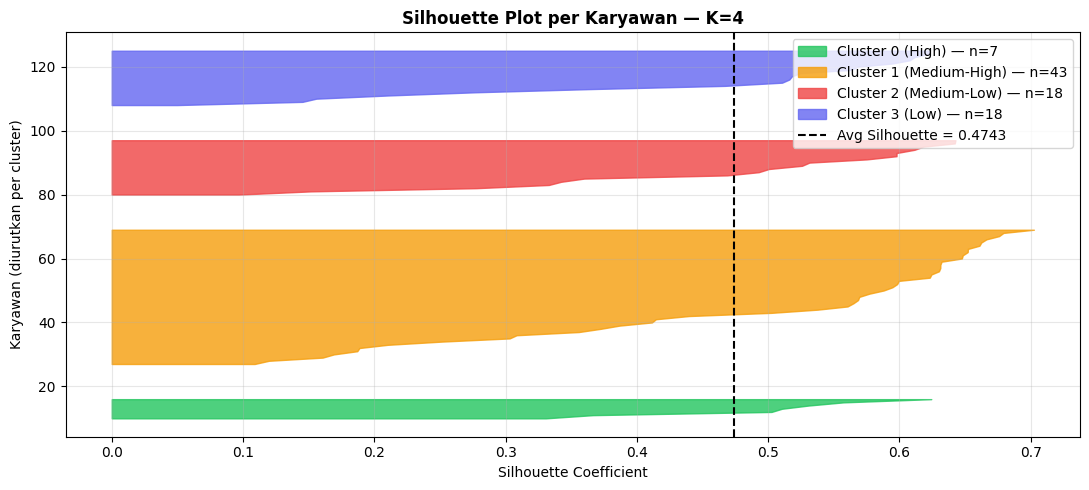


Karyawan dengan Silhouette < 0 (ambigu): 0


In [39]:
sil = silhouette_score(X_scaled, labels_final)
dbi = davies_bouldin_score(X_scaled, labels_final)
sse = kmeans_final.inertia_

if sil >= 0.70:   sil_interp = 'Sangat kuat'
elif sil >= 0.50: sil_interp = 'Cukup baik'
elif sil >= 0.25: sil_interp = 'Lemah'
else:             sil_interp = 'Tidak berarti'

if dbi < 0.5:   dbi_interp = 'Sangat baik'
elif dbi < 1.0: dbi_interp = 'Baik'
elif dbi < 1.5: dbi_interp = 'Cukup'
else:           dbi_interp = 'Buruk'

print('=' * 50)
print(f'    EVALUASI MODEL K-MEANS  (k={BEST_K})')
print('=' * 50)
print(f'  Silhouette Score     : {sil:.4f}  → {sil_interp}')
print(f'  Davies-Bouldin Index : {dbi:.4f}  → {dbi_interp}')
print(f'  Inertia (SSE)        : {sse:.2f}')
print('=' * 50)
print('  Catatan:')
print('  - Silhouette > 0.5 = cluster cukup terpisah')
print('  - DBI < 1.0        = cluster tidak tumpang tindih')
print('=' * 50)

#  Silhouette per karyawan 
sil_samples = silhouette_samples(X_scaled, labels_final)
df_grouped['silhouette_sample'] = sil_samples

ordered_labels = list(rank_labels.items())  # [(cid, label)] urut visit desc

palette = ['#22c55e', '#f59e0b', '#ef4444', '#6366f1',
           '#ec4899', '#14b8a6', '#f97316', '#8b5cf6', '#06b6d4']

fig, ax = plt.subplots(figsize=(11, 5))
y_lower = 10
for idx, (cid, lbl) in enumerate(ordered_labels):
    vals    = np.sort(sil_samples[labels_final == cid])
    size    = vals.shape[0]
    y_upper = y_lower + size
    color   = palette[idx % len(palette)]
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals,
                     facecolor=color, edgecolor=color, alpha=0.8,
                     label=f'Cluster {cid} ({lbl}) — n={size}')
    y_lower = y_upper + 10

ax.axvline(x=sil, color='black', linestyle='--', linewidth=1.5,
           label=f'Avg Silhouette = {sil:.4f}')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Karyawan (diurutkan per cluster)')
ax.set_title(f'Silhouette Plot per Karyawan — K={BEST_K}', fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('plot_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

ambiguous = df_grouped[df_grouped['silhouette_sample'] < 0][
    ['Username', 'cluster_label', 'silhouette_sample']]
print(f'\nKaryawan dengan Silhouette < 0 (ambigu): {len(ambiguous)}')
if len(ambiguous) > 0:
    print(ambiguous.sort_values('silhouette_sample').head(10).to_string(index=False))

## 7. Analisis Karakteristik Cluster

=== Rata-rata Fitur per Cluster ===
             visit_count  Facing  Is FIFO/FEFO  Is Price Tag Available
Cluster                                                               
High           24306.429   1.052           0.0                     0.0
Medium-High    14283.512   0.959           0.0                     0.0
Medium-Low      8591.389   1.757           0.0                     0.0
Low             6058.778   0.587           0.0                     0.0

Jumlah karyawan per cluster:
cluster_label
Medium-High    43
Low            18
Medium-Low     18
High            7
Name: count, dtype: int64


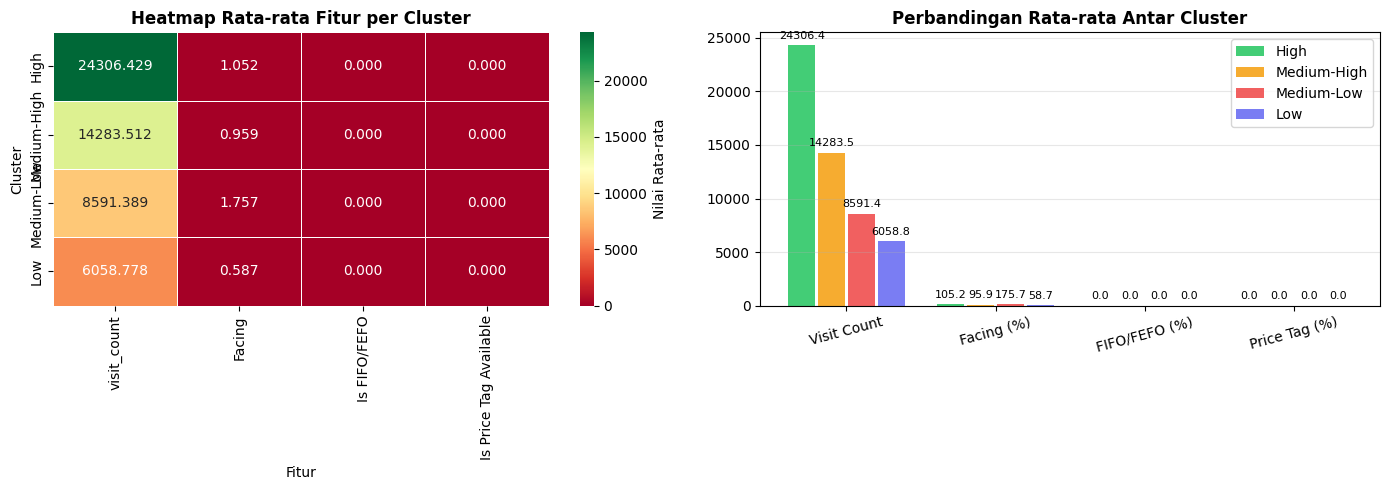

In [40]:
label_order     = [lbl for _, lbl in ordered_labels]
cluster_summary = (
    df_grouped.groupby('cluster_label')[feature_cols]
              .mean()
              .round(3)
              .reindex(label_order)
)
cluster_summary.index.name = 'Cluster'

print('=== Rata-rata Fitur per Cluster ===')
print(cluster_summary)
print(f'\nJumlah karyawan per cluster:')
print(df_grouped['cluster_label'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cluster_summary, annot=True, fmt='.3f', cmap='RdYlGn',
            linewidths=0.5, ax=axes[0], cbar_kws={'label': 'Nilai Rata-rata'})
axes[0].set_title('Heatmap Rata-rata Fitur per Cluster', fontweight='bold')
axes[0].set_xlabel('Fitur')

x     = np.arange(len(feature_cols))
width = 0.8 / BEST_K
for idx, lbl in enumerate(label_order):
    offset = (idx - (BEST_K - 1) / 2) * width
    vals   = cluster_summary.loc[lbl].values.copy()
    vals[1:] *= 100   # Facing, FIFO, PriceTag → persen
    bars = axes[1].bar(x + offset, vals, width * 0.9,
                       label=lbl, color=palette[idx % len(palette)], alpha=0.85)
    axes[1].bar_label(bars, fmt='%.1f', padding=3, fontsize=8)

axes[1].set_xticks(x)
axes[1].set_xticklabels(['Visit Count', 'Facing (%)', 'FIFO/FEFO (%)', 'Price Tag (%)'],
                         rotation=15)
axes[1].set_title('Perbandingan Rata-rata Antar Cluster', fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('plot_karakteristik_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Scatter Plot Cluster

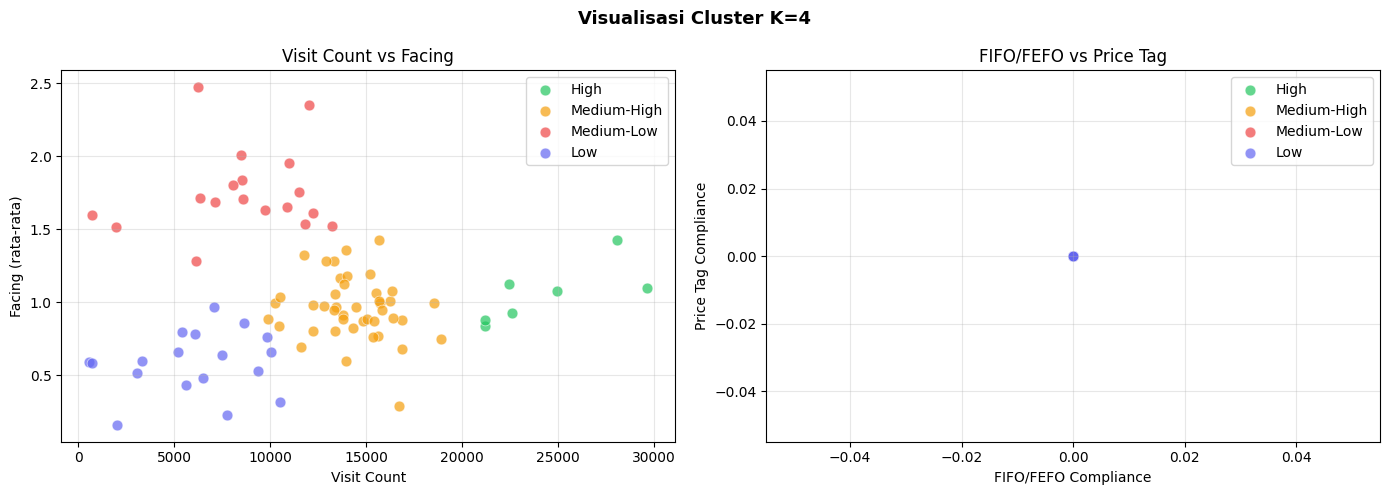

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Visualisasi Cluster K={BEST_K}', fontsize=13, fontweight='bold')

for idx, (cid, lbl) in enumerate(ordered_labels):
    mask  = df_grouped['cluster_label'] == lbl
    color = palette[idx % len(palette)]
    axes[0].scatter(df_grouped.loc[mask, 'visit_count'],
                    df_grouped.loc[mask, 'Facing'],
                    c=color, label=lbl, alpha=0.7, s=60,
                    edgecolors='white', linewidth=0.5)
    axes[1].scatter(df_grouped.loc[mask, 'Is FIFO/FEFO'],
                    df_grouped.loc[mask, 'Is Price Tag Available'],
                    c=color, label=lbl, alpha=0.7, s=60,
                    edgecolors='white', linewidth=0.5)

axes[0].set_xlabel('Visit Count')
axes[0].set_ylabel('Facing (rata-rata)')
axes[0].set_title('Visit Count vs Facing')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_xlabel('FIFO/FEFO Compliance')
axes[1].set_ylabel('Price Tag Compliance')
axes[1].set_title('FIFO/FEFO vs Price Tag')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plot_scatter_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Heatmap Korelasi Antar Fitur

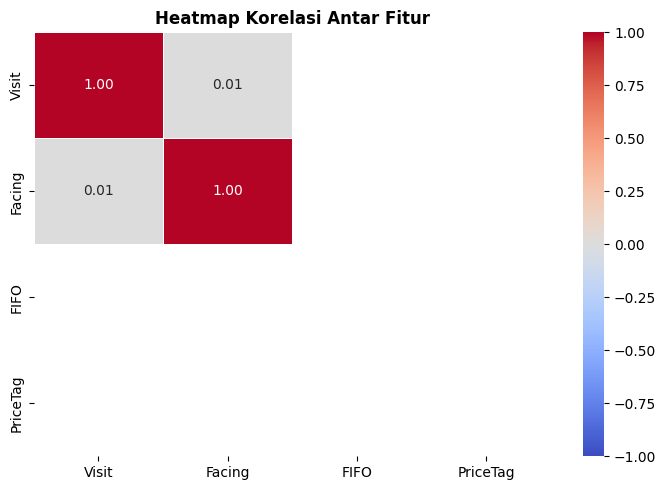

In [42]:
plt.figure(figsize=(7, 5))
corr = df_grouped[feature_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1,
            xticklabels=['Visit', 'Facing', 'FIFO', 'PriceTag'],
            yticklabels=['Visit', 'Facing', 'FIFO', 'PriceTag'])
plt.title('Heatmap Korelasi Antar Fitur', fontweight='bold')
plt.tight_layout()
plt.savefig('plot_korelasi.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Export Hasil & Simpan Model

In [43]:
final_df = employee_info.merge(df_grouped, on='Username', how='right')
final_df['silhouette_sample'] = final_df['silhouette_sample'].round(4)

output_path = f'hasil_clustering_k{BEST_K}.xlsx'
final_df.to_excel(output_path, index=False)
print(f'Hasil disimpan ke: {output_path}')
print(f'   Total baris : {len(final_df)}')
print(f'   Kolom       : {final_df.columns.tolist()}')

os.makedirs('models', exist_ok=True)
joblib.dump(kmeans_final, 'models/kmeans_model.pkl')
joblib.dump(scaler,       'models/minmax_scaler.pkl')
print('Model  disimpan ke models/kmeans_model.pkl')
print('Scaler disimpan ke models/minmax_scaler.pkl')

# label_order dibutuhkan app.py untuk urutan tampilan tier
meta = {
    'k'              : BEST_K,
    'output_file'    : output_path,
    'k_selection'    : {
        'silhouette'   : best_sil_k,
        'davies_bouldin': best_dbi_k,
        'winner'       : BEST_K,
    },
    'cluster_labels' : {str(k): v for k, v in rank_labels.items()},
    'label_order'    : [rank_labels[cid] for cid, _ in cluster_visit_mean.items()],
    'silhouette_score': round(sil, 4),
    'davies_bouldin'  : round(dbi, 4),
    'inertia'         : round(sse, 2),
    'n_karyawan'      : len(final_df),
}
with open('cluster_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('Metadata disimpan ke cluster_meta.json')
print(json.dumps(meta, indent=2))

Hasil disimpan ke: hasil_clustering_k4.xlsx
   Total baris : 86
   Kolom       : ['Username', 'Nama Karyawan', 'Area', 'Region', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available', 'visit_count', 'cluster', 'cluster_label', 'silhouette_sample']
Model  disimpan ke models/kmeans_model.pkl
Scaler disimpan ke models/minmax_scaler.pkl
Metadata disimpan ke cluster_meta.json
{
  "k": 4,
  "output_file": "hasil_clustering_k4.xlsx",
  "k_selection": {
    "silhouette": 4,
    "davies_bouldin": 4,
    "winner": 4
  },
  "cluster_labels": {
    "0": "High",
    "1": "Medium-High",
    "2": "Medium-Low",
    "3": "Low"
  },
  "label_order": [
    "High",
    "Medium-High",
    "Medium-Low",
    "Low"
  ],
  "silhouette_score": 0.4743,
  "davies_bouldin": 0.6582,
  "inertia": 1.55,
  "n_karyawan": 86
}


## 11. Ringkasan Akhir

In [44]:
print('=' * 55)
print(f'     RINGKASAN HASIL CLUSTERING K={BEST_K}')
print('=' * 55)
print(f'  Total karyawan dianalisis : {len(final_df)}')
for lbl in label_order:
    n_k = (final_df['cluster_label'] == lbl).sum()
    print(f'  Cluster {lbl:<14}: {n_k} karyawan')
print()
print('  --- Evaluasi Model ---')
print(f'  Silhouette Score     : {sil:.4f}  → {sil_interp}')
print(f'  Davies-Bouldin Index : {dbi:.4f}  → {dbi_interp}')
print(f'  Inertia (SSE)        : {sse:.2f}')
print()
print('  --- Karakteristik Cluster ---')
for lbl in label_order:
    sub = df_grouped[df_grouped['cluster_label'] == lbl]
    print(f'  [{lbl:<14}] visit={sub["visit_count"].mean():.1f} | '
          f'facing={sub["Facing"].mean()*100:.1f}% | '
          f'fifo={sub["Is FIFO/FEFO"].mean()*100:.1f}% | '
          f'price={sub["Is Price Tag Available"].mean()*100:.1f}%')
print('=' * 55)

     RINGKASAN HASIL CLUSTERING K=4
  Total karyawan dianalisis : 86
  Cluster High          : 7 karyawan
  Cluster Medium-High   : 43 karyawan
  Cluster Medium-Low    : 18 karyawan
  Cluster Low           : 18 karyawan

  --- Evaluasi Model ---
  Silhouette Score     : 0.4743  → Lemah
  Davies-Bouldin Index : 0.6582  → Baik
  Inertia (SSE)        : 1.55

  --- Karakteristik Cluster ---
  [High          ] visit=24306.4 | facing=105.2% | fifo=0.0% | price=0.0%
  [Medium-High   ] visit=14283.5 | facing=95.9% | fifo=0.0% | price=0.0%
  [Medium-Low    ] visit=8591.4 | facing=175.7% | fifo=0.0% | price=0.0%
  [Low           ] visit=6058.8 | facing=58.7% | fifo=0.0% | price=0.0%
